---
title: "3.9 Análisis multiamenaza"
short_title: "3.9 Multiamenaza"
subtitle: "Pérdida, personas y servicios en un solo marco: tres cadenas de detonantes, curvas de excedencia y bandas de incertidumbre"
description: "Evaluación cuantitativa de riesgo multiamenaza para Leticia adaptada de Chen et al. (2016): escenarios por detonante, regla del máximo por edificación y curvas de excedencia mínima, media y máxima."
keywords: [multiamenaza, curva de excedencia, pérdida anual esperada, detonante, ENSO, Leticia]
---

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mromerot/leticia/blob/main/book/03_analisis/39_multiamenaza.ipynb)

In [1]:
# Preparación del entorno. En Colab instala el paquete del proyecto desde GitHub (1–2 minutos);
# en una copia local usa el paquete ya instalado con `pip install -e .`.
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "leticia @ git+https://github.com/mromerot/leticia"], check=True)
from leticia.libro import preparar, intentar
preparar()

Los flujos 3.1 a 3.7 evalúan cada amenaza por separado. Esta página las reúne con el flujo de seis etapas de la
sección [1.1](../01_conceptos/11_marco_riesgo.md) ({numref}`fig-flujo-multiamenaza`), adaptado de Chen et al.
[@chen2016multihazard]. Responde tres preguntas que ninguna amenaza responde sola: **cuánto se pierde al año** en
conjunto, **a cuántas personas** alcanza cada tipo de evento y **cuántos días** se interrumpen los servicios, con un
rango de incertidumbre en cada cifra.

:::{important} Cómo leer las cifras
Los daños y las personas de esta página dependen de supuestos de `parametros.yaml` (sección `multiamenaza`) que son
**ilustrativos**: son la hipótesis de trabajo del libro, no valores validados con la Alcaldía ni con expertos locales.
Por eso cada ingrediente se calcula en una versión mínima, media y máxima, y las conclusiones se apoyan en el **orden
de magnitud y en la comparación entre cadenas**, no en la cifra puntual.
:::

In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy import stats

from leticia import aoi, clima, espacial, exposicion, fuentes, hidro, indicadores, multiamenaza as mm, riesgo, viz
from leticia.config import parametros

P = parametros()
PM = P["multiamenaza"]
BANDAS = mm.BANDAS
COL_BANDA = {"minimo": "#9ecae1", "medio": "#2171b5", "maximo": "#08306b"}
def f(x, d=0):
    """Número con punto de miles."""
    return f"{x:,.{d}f}".replace(",", ".")

## 1. Tres cadenas de detonantes (etapas 1 y 2)

Una misma causa dispara varias amenazas a la vez. Para decidir qué amenazas se combinan, la agrupación debe
apoyarse en los datos y no solo en el criterio: ¿se asocian de verdad las crecientes, las vaciantes y los eventos
registrados con la fase del ENSO?

,años,media_máximo_m,media_mínimo_m
fase ENSO,,,
La Niña,9,17.25,6.95
neutro,10,16.92,8.51
El Niño,7,16.40,5.55


**Asociación entre el ONI y el nivel del río** según la ventana del ONI (la de diciembre a febrero es el pico del ENSO, que precede a la temporada de aguas bajas):

años  Spearman    p
ventana del ONI nivel                            
ONI dic–feb     máximo anual    26     -0.33 0.09
                mínimo anual    26     -0.25 0.23
ONI ago–dic     máximo anual    26      0.04 0.83
                mínimo anual    26      0.42 0.03

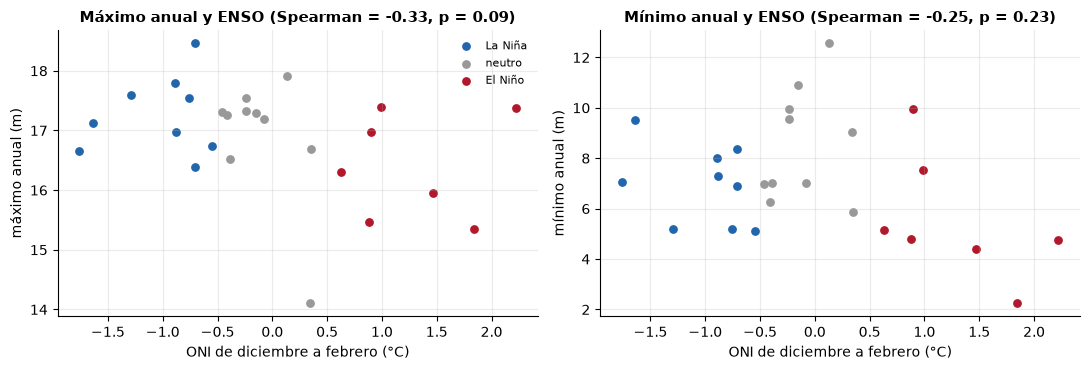

In [3]:
nivel = hidro.limpiar_nivel(fuentes.nivel_rio())
oni = fuentes.oni()
fase = mm.fase_enso(oni)
maximos = hidro.extremos_anuales(nivel, "max")["valor"] / 100
minimos = hidro.extremos_anuales(nivel, "min")["valor"] / 100
anual = pd.DataFrame({"máximo anual (m)": maximos, "mínimo anual (m)": minimos, "fase ENSO": fase}).dropna()
anual["ONI dic–feb"] = mm.oni_pico(oni)
ago_dic = oni[oni.index.month.isin([8, 9, 10, 11, 12])]
anual["ONI ago–dic"] = ago_dic.groupby(ago_dic.index.year).mean()
r_max = stats.spearmanr(anual["ONI dic–feb"], anual["máximo anual (m)"])
r_min = stats.spearmanr(anual["ONI dic–feb"], anual["mínimo anual (m)"])
filas_r = []
for ventana in ["ONI dic–feb", "ONI ago–dic"]:
    for col in ["máximo anual (m)", "mínimo anual (m)"]:
        d_ = anual[[ventana, col]].dropna()
        r_ = stats.spearmanr(d_[ventana], d_[col])
        filas_r.append({"ventana del ONI": ventana, "nivel": col.split(" (")[0], "años": len(d_), "Spearman": r_.statistic, "p": r_.pvalue})
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
colores = {"La Niña": "#2166ac", "neutro": "#999999", "El Niño": "#b2182b"}
for a, col, r in zip(ax, ["máximo anual (m)", "mínimo anual (m)"], [r_max, r_min]):
    for fs, g in anual.groupby("fase ENSO", observed=True):
        a.scatter(g["ONI dic–feb"], g[col], color=colores[fs], label=fs, s=28)
    a.set_xlabel("ONI de diciembre a febrero (°C)")
    a.set_ylabel(col)
    a.set_title(f"{col.split(' (')[0].capitalize()} y ENSO (Spearman = {r.statistic:+.2f}, p = {r.pvalue:.2f})")
ax[0].legend(fontsize=8)
fig.tight_layout()
resumen = anual.groupby("fase ENSO", observed=True).agg(años=("ONI dic–feb", "size"), media_máximo_m=("máximo anual (m)", "mean"),
                                                        media_mínimo_m=("mínimo anual (m)", "mean"))
display(resumen.round(2))
display(Markdown("**Asociación entre el ONI y el nivel del río** según la ventana del ONI (la de diciembre a febrero es el pico del ENSO, que precede a la temporada de aguas bajas):"))
display(pd.DataFrame(filas_r).set_index(["ventana del ONI", "nivel"]).round(2))

In [4]:
viz.pie(viz.nota_fuente("nivel_rio_leticia", "indices_oceanicos") + " ONI de diciembre a febrero; El Niño o La Niña cuando |ONI| > 0,5 °C.")

*Fuente: IDEAM — Estación limnimétrica LETICIA [48017010], series NV_MEDIA_D, NV_MN_D y NV_MX_D; NOAA Climate Prediction Center — ONI (ERSSTv5), trimestres móviles 1950–presente. ONI de diciembre a febrero; El Niño o La Niña cuando |ONI| > 0,5 °C.*

In [5]:
te = intentar(indicadores.tabla_eventos, mensaje="DesInventar no respondió; la tabla de eventos por fase del ENSO queda para una ejecución posterior")
if te is not None:
  te = te[te["categoria"].isin(["Inundación", "Sequía y desabastecimiento", "Erosión y movimientos en masa", "Incendio de cobertura vegetal", "Vendaval y lluvias"])]
  te = te.assign(año=te.index.year)
  te["fase ENSO"] = te["año"].map(fase)
  tabla_e = te.dropna(subset=["fase ENSO"]).pivot_table(index="categoria", columns="fase ENSO", values="evento", aggfunc="count", fill_value=0, observed=True)
  anios_fase = fase.loc[te["año"].min():].value_counts()
  tabla_e.loc["años en la fase"] = [anios_fase.get(c, 0) for c in tabla_e.columns]
  display(Markdown("**Eventos registrados (DesInventar y UNGRD) según la fase del ENSO del año:**"))
  display(tabla_e.astype(int))

:::{warning}
DesInventar no respondió; la tabla de eventos por fase del ENSO queda para una ejecución posterior: `HTTPError: 503 Server Error: Service Unavailable for url: https://www.desinventar.net/DesInventar/download/DI_export_col.zip`
:::

**Lectura.** La asociación entre el ENSO y el nivel del río va en la dirección esperada, pero es **débil**. Con el ONI
de diciembre a febrero (el pico del ENSO, que precede a las aguas bajas), los máximos anuales son algo más altos en
La Niña (17,3 m en promedio frente a 16,4 m en El Niño) y los mínimos más bajos en El Niño (5,6 m frente a 8,5 m en
años neutros). Pero las correlaciones de Spearman (−0,33 y −0,25 con 26 años) no son significativas al 5 %, y con el
ONI de agosto a diciembre, que ya refleja el final del evento, el signo del mínimo se invierte. La vaciante récord
de 2024 llegó después del pico de El Niño de 2023–2024, no durante él. Por eso la agrupación por detonante es una
**hipótesis de trabajo**: sirve para decidir qué amenazas se combinan, no para suponer que ocurren los mismos años.

## 2. Escenarios por detonante: el periodo de retorno compartido (etapa 2)

Cada cadena tiene un periodo de retorno propio, que se estima con la serie de su detonante, y todas las amenazas de la
cadena se evalúan con ese mismo periodo. La cadena de la **creciente** usa los mapas de profundidad del JRC; la de la
**lluvia** usa la lluvia máxima diaria de ERA5; la del **ENSO** usa el nivel mínimo del río.

In [6]:
T_jrc = P["inundacion"]["periodos_jrc"]
T_lluvia = PM["lluvia"]["periodos"]
era = fuentes.clima_diario()
era = era[era.index.year < pd.Timestamp.today().year]
rx1 = clima.indices_lluvia(era["precipitation_sum"], P["lluvias"]["umbral_lluvia_fuerte_mm"])["rx1day"].loc[1980:]
ret_lluvia = hidro.niveles_retorno_ic(rx1.values, T_lluvia)
ret_nivel_max = hidro.niveles_retorno_ic(maximos.values * 100, T_jrc)
ret_nivel_min = hidro.niveles_retorno_ic(minimos.values * 100, [2, 5, 10, 25, 50, 100], minimos=True)
display(Markdown("**Creciente: nivel máximo anual en la regla de Leticia (m) por periodo de retorno** (GEV, L-momentos):"))
display((ret_nivel_max / 100).round(2).rename(columns={"nivel": "nivel (m)", "ic5": "IC 5 %", "ic95": "IC 95 %"}))
display(Markdown("**Lluvia: precipitación máxima diaria (mm/día)**, ERA5 1980–presente:"))
display(ret_lluvia.round(0).rename(columns={"nivel": "mm/día", "ic5": "IC 5 %", "ic95": "IC 95 %"}))
display(Markdown("**ENSO: nivel mínimo anual en la regla de Leticia (m)**:"))
display((ret_nivel_min / 100).round(2).rename(columns={"nivel": "nivel (m)", "ic5": "IC 5 %", "ic95": "IC 95 %"}))

**Creciente: nivel máximo anual en la regla de Leticia (m) por periodo de retorno** (GEV, L-momentos):

,nivel (m),IC 5 %,IC 95 %
periodo_retorno,,,
10,18.05,17.76,18.30
20,18.23,17.88,18.53
50,18.37,17.95,18.78
100,18.43,17.97,18.91
200,18.48,18.00,19.05
500,18.52,18.02,19.18


**Lluvia: precipitación máxima diaria (mm/día)**, ERA5 1980–presente:

,mm/día,IC 5 %,IC 95 %
periodo_retorno,,,
2,45.00,40.00,50.00
5,63.00,55.00,73.00
10,78.00,66.00,89.00
25,101.00,82.00,114.00
50,121.00,95.00,138.00
100,144.00,108.00,168.00


**ENSO: nivel mínimo anual en la regla de Leticia (m)**:

,nivel (m),IC 5 %,IC 95 %
periodo_retorno,,,
2,7.00,6.20,7.92
5,5.05,4.42,5.91
10,4.20,3.43,5.15
25,3.44,2.18,4.61
50,3.04,1.32,4.45
100,2.75,0.68,4.34


In [7]:
viz.pie(viz.nota_fuente("nivel_rio_leticia", "clima_diario", "inundacion_jrc") + " Intervalos de confianza por remuestreo.")

*Fuente: IDEAM — Estación limnimétrica LETICIA [48017010], series NV_MEDIA_D, NV_MN_D y NV_MX_D; ECMWF ERA5 (vía Open-Meteo) — Reanálisis ERA5, celda 0,25°; JRC – Copernicus EMS (GloFAS) — Global river flood hazard maps v2.1 (RP10–RP500), LISFLOOD-FP. Intervalos de confianza por remuestreo.*

## 3. Elementos en riesgo (etapa 3)

La exposición es la misma de los flujos 3.1 a 3.7: las huellas de edificaciones de Microsoft, con la población de Kontur
repartida entre ellas ([2.6](../02_datos/26_area_estudio.ipynb)). El valor de cada edificación es su área por un costo
de reposición con tres valores (mínimo, medio y máximo).

In [8]:
edif = exposicion.edificaciones_urbanas().copy()
malla = exposicion.malla_exposicion()
pts = edif.representative_point().to_crs(4326)
area = edif["area_m2"].values
personas = edif["poblacion"].values
valor = {b: area * mm.valor_banda("costo_reposicion_cop_m2", b) for b in BANDAS}
display(pd.DataFrame({
    "edificaciones": [len(edif)], "personas": [personas.sum()],
    **{f"valor {b} (miles de millones COP)": [valor[b].sum() / 1e9] for b in BANDAS}}, index=["Leticia (casco urbano)"]).round(0))

,edificaciones,personas,valor minimo (miles de millones COP),valor medio (miles de millones COP),valor maximo (miles de millones COP)
Leticia (casco urbano),6808,"46,507.00","1,271.00","1,907.00","2,542.00"


## 4. Cadena de la creciente: inundación y erosión de orillas (etapas 4 y 5)

La creciente inunda las zonas bajas y, al bajar las aguas, socava los barrancos de la orilla. Una edificación puede
sufrir las dos en el mismo ciclo, y por eso su pérdida es la **mayor** de las dos y no su suma
([1.1](../01_conceptos/11_marco_riesgo.md)).

In [9]:
prof_rp = {}
for t in T_jrc:
    d = fuentes.inundacion_jrc(t)
    prof_rp[t] = np.nan_to_num(d.interp(x=("p", pts.x.values), y=("p", pts.y.values), method="nearest").values)
# Franja de orilla activa: misma definición que 3.3.c
pe = P["erosion"]
ds = espacial.compuesto_landsat(pe["anios_comparacion"][-1], pe["meses_aguas_bajas"])
agua = (espacial.mndwi(ds) > pe["umbral_mndwi"]).rio.write_crs(4326)
orilla = espacial.vectorizar(agua, 200).to_crs(aoi.crs()).boundary.union_all()
zona = orilla.buffer(pe["franja_orilla_m"]).intersection(aoi.area_urbana().geometry.iloc[0])
en_orilla = edif.representative_point().within(zona).values
display(Markdown(f"Edificaciones dentro de la franja de {pe['franja_orilla_m']} m de la orilla: **{f(en_orilla.sum())}** "
                 f"({f(personas[en_orilla].sum())} personas)."))

Edificaciones dentro de la franja de 150 m de la orilla: **83** (416 personas).

In [10]:
def perdida_creciente(banda, t, con_erosion=True, regla="maximo"):
    f_inund = mm.fraccion_danio_banda(prof_rp[t], banda) * (prof_rp[t] >= mm.valor_banda("profundidad_minima_m", banda))
    f_eros = en_orilla * mm.valor_banda("erosion_fraccion_perdida", banda) if con_erosion else np.zeros(len(edif))
    comb = mm.combinar_maximo if regla == "maximo" else mm.combinar_suma_acotada
    return comb(f_inund, f_eros), f_inund, f_eros

curvaA = {b: pd.Series({t: (perdida_creciente(b, t)[0] * valor[b]).sum() / 1e6 for t in T_jrc}) for b in BANDAS}
solo_inund = {b: pd.Series({t: (perdida_creciente(b, t, con_erosion=False)[0] * valor[b]).sum() / 1e6 for t in T_jrc}) for b in BANDAS}
suma = {b: pd.Series({t: (perdida_creciente(b, t, regla="suma")[0] * valor[b]).sum() / 1e6 for t in T_jrc}) for b in BANDAS}
tabla_A = pd.DataFrame({f"{b}": curvaA[b] for b in BANDAS})
tabla_A.index.name = "periodo de retorno (años)"
display(Markdown("**Pérdida por creciente (millones de COP), inundación y erosión combinadas con el máximo:**"))
display(tabla_A.round(0))
pae_A = mm.bandas_pae(curvaA)
pae_inund = mm.bandas_pae(solo_inund)
pae_suma = mm.bandas_pae(suma)
display(pd.DataFrame({"inundación sola": pae_inund, "inundación + erosión (máximo)": pae_A, "inundación + erosión (suma)": pae_suma}).round(0)
        .rename_axis("banda"))

**Pérdida por creciente (millones de COP), inundación y erosión combinadas con el máximo:**

,minimo,medio,maximo
periodo de retorno (años),,,
10,"112,568.00","215,125.00","305,089.00"
20,"141,443.00","265,886.00","373,057.00"
50,"162,922.00","306,417.00","424,420.00"
100,"178,733.00","335,443.00","461,952.00"
200,"193,752.00","365,976.00","502,985.00"
500,"256,776.00","483,828.00","668,473.00"


,inundación sola,inundación + erosión (máximo),inundación + erosión (suma)
banda,,,
minimo,"19,859.00","19,859.00","19,931.00"
medio,"37,604.00","37,604.00","37,604.00"
maximo,"52,772.00","52,772.00","52,772.00"


**Personas expuestas a la creciente, banda media:** sumar las dos amenazas cuenta dos veces a quien está en ambas.

,suma de las dos amenazas,sin repetir (unión)
periodo de retorno (años),,
10,"4,266.00","3,850.00"
20,"4,861.00","4,445.00"
50,"5,364.00","4,948.00"
100,"5,873.00","5,456.00"
200,"6,438.00","6,021.00"
500,"8,931.00","8,515.00"


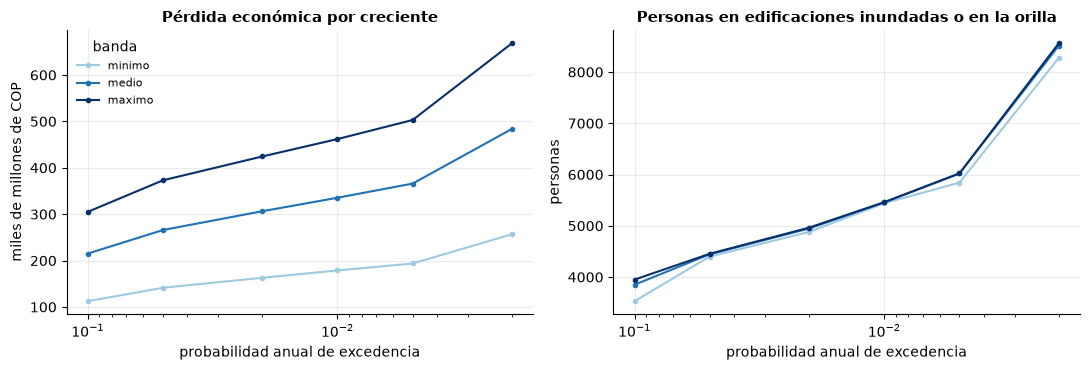

In [11]:
prob = lambda c: 1 / c.index.to_numpy(dtype=float)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for b in BANDAS:
    ax[0].plot(1 / np.array(T_jrc), curvaA[b].values / 1e3, marker="o", ms=3, color=COL_BANDA[b], label=b)
ax[0].set_xscale("log"); ax[0].invert_xaxis()
ax[0].set_xlabel("probabilidad anual de excedencia"); ax[0].set_ylabel("miles de millones de COP")
ax[0].set_title("Pérdida económica por creciente"); ax[0].legend(title="banda", fontsize=8)
pers_infl = {b: pd.Series({t: personas[(prof_rp[t] >= mm.valor_banda("profundidad_minima_m", b))].sum() for t in T_jrc}) for b in BANDAS}
pers_union = {b: pd.Series({t: personas[(prof_rp[t] >= mm.valor_banda("profundidad_minima_m", b)) | en_orilla].sum() for t in T_jrc}) for b in BANDAS}
for b in BANDAS:
    ax[1].plot(1 / np.array(T_jrc), pers_union[b].values, marker="o", ms=3, color=COL_BANDA[b], label=b)
ax[1].set_xscale("log"); ax[1].invert_xaxis()
ax[1].set_xlabel("probabilidad anual de excedencia"); ax[1].set_ylabel("personas")
ax[1].set_title("Personas en edificaciones inundadas o en la orilla")
fig.tight_layout()
exceso = pd.DataFrame({"suma de las dos amenazas": [pers_infl["medio"][t] + personas[en_orilla].sum() for t in T_jrc],
                       "sin repetir (unión)": [pers_union["medio"][t] for t in T_jrc]}, index=T_jrc)
exceso.index.name = "periodo de retorno (años)"
display(Markdown("**Personas expuestas a la creciente, banda media:** sumar las dos amenazas cuenta dos veces a quien está en ambas."))
display(exceso.round(0))

In [12]:
viz.pie(viz.nota_fuente("inundacion_jrc", "edificaciones", "poblacion", "landsat") + " Curva de Huizinga et al. (2017); parámetros ilustrativos de `multiamenaza`.")

*Fuente: JRC – Copernicus EMS (GloFAS) — Global river flood hazard maps v2.1 (RP10–RP500), LISFLOOD-FP; Microsoft – Global ML Building Footprints — Huellas derivadas de imágenes (2014–2024), particionadas por quadkey; Kontur (GHSL, Facebook HRSL, Microsoft Buildings, Copernicus) — Kontur Population Colombia 2023-11-01; USGS / NASA (Microsoft Planetary Computer) — Landsat Collection 2 Level-2 (reflectancia y temperatura de superficie). Curva de Huizinga et al. (2017); parámetros ilustrativos de `multiamenaza`.*

**Lectura.** La erosión **no suma pérdida económica** en esta cadena: las 83 edificaciones de la franja de orilla ya
tienen un daño por inundación mayor que la fracción de pérdida que se supone para la erosión (5 % a 40 %), así que el
máximo coincide con la inundación sola y la suma apenas la sobrestima (0,4 % en la banda mínima). En **personas** la
regla sí importa: sumar las dos amenazas cuenta unas 400 personas dos veces (4 266 frente a 3 850 con la creciente
de 10 años, 11 % más). La pérdida por creciente va de unos 215 000 millones de COP (T = 10 años) a 484 000 millones
(T = 500) en la banda media, con un rango de 113 000 a 305 000 millones a T = 10; la pérdida anual esperada de la
cadena es de unos 37 600 millones de COP por año, entre 19 900 y 52 800. Estas cifras son un techo: el contraste de
la sección 5 muestra que el mapa del JRC pone agua en muchas más edificaciones que las que reportan las emergencias.

## 5. Cadena de la lluvia intensa: encharcamiento y vendavales (etapas 4 y 5)

Un aguacero encharca las depresiones del terreno y, cuando trae viento, levanta cubiertas. El encharcamiento se mapea
con las depresiones del modelo de elevación; los vendavales no se pueden mapear (el catastro no registra el material
de las cubiertas), así que se estiman con los **daños registrados**. Los dos dañan componentes distintos de la
vivienda (el piso y los enseres frente a la cubierta), por eso se suman.

In [13]:
dem = fuentes.raster_estatico("cop-dem-glo-30", "data")
b = fuentes.bbox("bbox_urbano", 0.01)
prof_dep = espacial.profundidad_depresiones(dem.sel(x=slice(b[0], b[2]), y=slice(b[3], b[1])))
edif["prof_depresion_m"] = np.nan_to_num(prof_dep.interp(x=("p", pts.x.values), y=("p", pts.y.values), method="nearest").values)
dep = edif["prof_depresion_m"].values
dep = np.where(dep >= 0.5, dep, 0)            # misma definición de depresión que 3.6.c
def perdida_lluvia(banda, t):
    prof = mm.profundidad_encharcamiento(dep, t, banda)
    return mm.fraccion_danio_banda(prof, banda) * (prof >= mm.valor_banda("profundidad_minima_m", banda)), prof
curvaB = {b: pd.Series({t: (perdida_lluvia(b, t)[0] * valor[b]).sum() / 1e6 for t in T_lluvia}) for b in BANDAS}
pers_B = {b: pd.Series({t: personas[perdida_lluvia(b, t)[1] >= mm.valor_banda("profundidad_minima_m", b)].sum() for t in T_lluvia}) for b in BANDAS}
tabla_B = pd.DataFrame(curvaB); tabla_B.index.name = "periodo de retorno (años)"
display(Markdown("**Pérdida por encharcamiento (millones de COP):**"))
display(tabla_B.round(0))
pae_B = mm.bandas_pae(curvaB)

**Pérdida por encharcamiento (millones de COP):**

,minimo,medio,maximo
periodo de retorno (años),,,
2,0.00,"9,214.00","79,641.00"
5,0.00,"20,927.00","107,849.00"
10,14.00,"33,736.00","133,850.00"
25,690.00,"61,127.00","182,293.00"
50,"2,386.00","86,134.00","224,424.00"
100,"5,838.00","110,429.00","261,304.00"


In [14]:
di = intentar(fuentes.desinventar, mensaje="DesInventar no respondió: los vendavales se estiman solo con la UNGRD (desde 2019)")
ung = fuentes.emergencias_ungrd()
partes = [ung[ung.evento.str.contains("VENDAVAL", na=False)][["viviendas_averiadas", "viviendas_destruidas", "personas"]].rename(
    columns={"viviendas_averiadas": "averiadas", "viviendas_destruidas": "destruidas", "personas": "afectados"})]
a0, a1 = PM["vendaval_anios"]
if di is not None:
    d_ = di[di.evento.str.contains("Vendaval", na=False) & (di.index.year < ung.index.year.min())]    # la UNGRD reemplaza a DesInventar desde 2019
    partes.append(d_[["vivafec", "vivdest", "afectados"]].rename(columns={"vivafec": "averiadas", "vivdest": "destruidas"}))
else:
    a0 = int(ung.index.year.min())
v = pd.concat(partes).sort_index()
v = v[(v.index.year >= a0) & (v.index.year <= a1)]
valor_vivienda = {b_: valor[b_].mean() for b_ in BANDAS}
serie_vend = {b_: mm.anual_empirico_vendaval(v, valor_vivienda[b_], mm.valor_banda("vendaval_fraccion_averiada", b_), range(a0, a1 + 1)) / 1e6 for b_ in BANDAS}
pae_vend = pd.Series({b_: mm.pae_empirica(serie_vend[b_]) for b_ in BANDAS})
pers_vend = v["afectados"].groupby(v.index.year).sum().reindex(range(a0, a1 + 1), fill_value=0)
display(Markdown(f"Vendavales registrados entre {a0} y {a1}: **{len(v)}** eventos en {int((pers_vend > 0).sum())} años de {a1 - a0 + 1}; "
                 f"{f(v['averiadas'].sum())} viviendas averiadas y {f(v['destruidas'].sum())} destruidas."))
display(pd.DataFrame({"pérdida anual esperada (millones COP/año)": pae_vend}).rename_axis("banda").round(0))

:::{warning}
DesInventar no respondió: los vendavales se estiman solo con la UNGRD (desde 2019): `HTTPError: 503 Server Error: Service Unavailable for url: https://www.desinventar.net/DesInventar/download/DI_export_col.zip`
:::

Vendavales registrados entre 2019 y 2025: **4** eventos en 3 años de 7; 172 viviendas averiadas y 0 destruidas.

,pérdida anual esperada (millones COP/año)
banda,
minimo,229.00
medio,"1,032.00"
maximo,"2,753.00"


### Contraste con los eventos registrados

La tercera fuente de vulnerabilidad de Chen et al. es el daño observado. La UNGRD registra pocas emergencias por
inundación en Leticia, pero permiten contrastar el **orden de magnitud** de lo modelado.

In [15]:
inund = ung[ung.evento == "INUNDACION"][["viviendas_averiadas", "viviendas_destruidas", "personas"]]
obs = (inund["viviendas_averiadas"] + inund["viviendas_destruidas"])
mod = pd.DataFrame({"edificaciones con agua (creciente, T = 10 años)": [int((prof_rp[10] >= mm.valor_banda("profundidad_minima_m", "medio")).sum())],
                    "edificaciones con agua (encharcamiento, T = 2 años)": [int((perdida_lluvia("medio", 2)[1] >= mm.valor_banda("profundidad_minima_m", "medio")).sum())],
                    "viviendas por emergencia de inundación (UNGRD, mediana)": [obs.median()],
                    "máximo registrado (UNGRD)": [obs.max()], "emergencias de inundación (UNGRD)": [len(obs)]}, index=["valor"]).T
display(mod.round(0))

,valor
"edificaciones con agua (creciente, T = 10 años)","1,240.00"
"edificaciones con agua (encharcamiento, T = 2 años)",236.00
"viviendas por emergencia de inundación (UNGRD, mediana)",159.00
máximo registrado (UNGRD),300.00
emergencias de inundación (UNGRD),4.00


**Lectura.** La banda del encharcamiento es la más ancha del cuaderno: la pérdida anual esperada va de 94 a 76 000
millones de COP por año, tres órdenes de magnitud, porque tres supuestos (el umbral de profundidad, el llenado de las
depresiones y la curva de daño) se combinan en el mismo sentido en cada extremo. El llenado de las depresiones se
**calibró** para que una lluvia de 2 años afecte unas 236 edificaciones, comparable a las 159 viviendas por emergencia
de inundación de la UNGRD (máximo 300). Es una calibración, no una validación: hay solo cuatro emergencias. El
contraste muestra además que el mapa del JRC para la creciente de 10 años pone agua en **1 240 edificaciones**, ocho
veces la mediana registrada: la pérdida de la cadena de la creciente debe leerse como un techo y no como una
estimación central. Los vendavales pesan poco en el registro disponible, que comienza en 2019 con la UNGRD.

## 6. Cadena del ENSO: sequía y estiaje, interrupción de servicios (etapas 4 y 5)

La sequía no destruye edificaciones: interrumpe **sistemas** ([3.2](32_sequia/index.md)). Su impacto se mide en días de
servicio perdido y en personas que dependen de ese servicio. El calor, el fuego y el dengue de la misma cadena son
amenazas de otra naturaleza y se leen en sus propias páginas; aquí se cuenta la interrupción del transporte fluvial
y del puerto, que es la que afecta a toda la ciudad.

Días medios por año bajo los umbrales: navegación restringida **30**, puerto aislado **6**; en 2024 fueron 86 y 52. Personas que dependen del transporte fluvial: **46.507**.

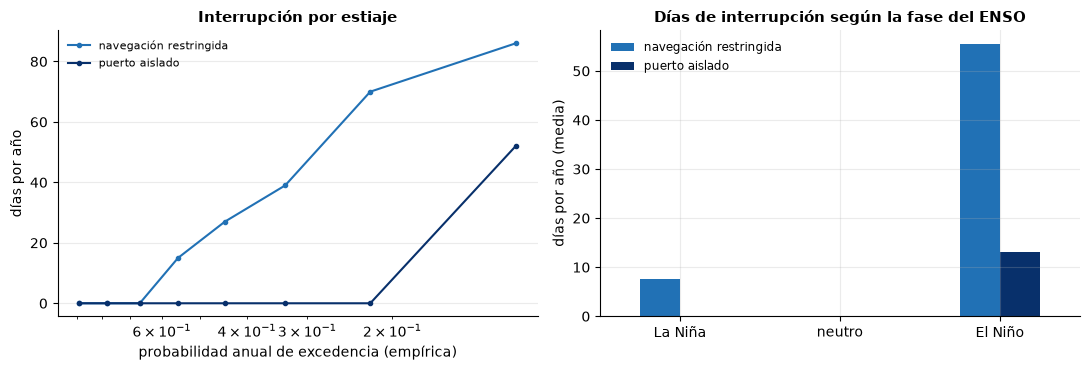

In [16]:
sv = PM["servicios"]
d_nav = hidro.dias_bajo_umbral(nivel, sv["umbral_navegacion_cm"])
d_aisl = hidro.dias_bajo_umbral(nivel, sv["umbral_aislamiento_cm"])
dias = pd.DataFrame({"navegación restringida": d_nav, "puerto aislado": d_aisl}).dropna()
dias["fase ENSO"] = fase.reindex(dias.index)
curvas_dias = {c: mm.curva_excedencia_empirica(dias[c]) for c in ["navegación restringida", "puerto aislado"]}
pob = malla["poblacion"].sum()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for c, col in zip(curvas_dias, ["#2171b5", "#08306b"]):
    ax[0].plot(curvas_dias[c]["prob_excedencia"], curvas_dias[c]["valor"], marker="o", ms=3, color=col, label=c)
ax[0].set_xscale("log"); ax[0].invert_xaxis()
ax[0].set_xlabel("probabilidad anual de excedencia (empírica)"); ax[0].set_ylabel("días por año")
ax[0].set_title("Interrupción por estiaje"); ax[0].legend(fontsize=8)
dias.groupby("fase ENSO", observed=True)[["navegación restringida", "puerto aislado"]].mean().plot.bar(ax=ax[1], color=["#2171b5", "#08306b"], rot=0)
ax[1].set_ylabel("días por año (media)"); ax[1].set_xlabel(""); ax[1].set_title("Días de interrupción según la fase del ENSO")
fig.tight_layout()
display(Markdown(f"Días medios por año bajo los umbrales: navegación restringida **{dias['navegación restringida'].mean():.0f}**, "
                 f"puerto aislado **{dias['puerto aislado'].mean():.0f}**; en 2024 fueron {int(dias.loc[2024, 'navegación restringida']) if 2024 in dias.index else 'n. d.'} "
                 f"y {int(dias.loc[2024, 'puerto aislado']) if 2024 in dias.index else 'n. d.'}. Personas que dependen del transporte fluvial: **{f(pob)}**.".replace(".0**", "**")))

In [17]:
viz.pie(viz.nota_fuente("nivel_rio_leticia", "indices_oceanicos", "poblacion") + " Umbrales en la regla de Leticia (`parametros.yaml`).")

*Fuente: IDEAM — Estación limnimétrica LETICIA [48017010], series NV_MEDIA_D, NV_MN_D y NV_MX_D; NOAA Climate Prediction Center — ONI (ERSSTv5), trimestres móviles 1950–presente; Kontur (GHSL, Facebook HRSL, Microsoft Buildings, Copernicus) — Kontur Population Colombia 2023-11-01. Umbrales en la regla de Leticia (`parametros.yaml`).*

**Lectura.** El estiaje es un riesgo de otra naturaleza: no destruye edificaciones, interrumpe servicios para toda
la ciudad. En un año promedio el río baja de 6 m unos 30 días y de 4 m unos 6; en 2024 fueron 86 y 52. Con la
distribución GEV, 4 m corresponde a un periodo de retorno cercano a 10 años (4,20 m, con un intervalo de confianza
de 3,4 a 5,2 m), y el mínimo de 2024 (2,24 m) quedó por debajo del nivel de 100 años ajustado (2,75 m), aunque ese
ajuste es muy incierto con 26 años de datos. Las 46 507 personas de la cabecera dependen del transporte fluvial, de
modo que la curva de personas de esta cadena es plana: todo o nada. Lo que cambia entre escenarios son los **días**.

## 7. Síntesis multiamenaza (etapa 6)

La pérdida anual esperada se suma entre cadenas porque sus detonantes son independientes en el tiempo: una creciente y
un aguacero extremo del mismo año son posibles, pero no se tratan como el mismo evento. Dentro de cada cadena ya se
aplicó el máximo.

In [18]:
pae = pd.DataFrame({"creciente (inundación + erosión)": pae_A, "lluvia: encharcamiento": pae_B, "lluvia: vendavales": pae_vend})
pae["total"] = pae.sum(axis=1)
pae.index.name = "banda"
display(Markdown("**Pérdida anual esperada por cadena (millones de COP por año):**"))
display(pae.round(0))
part = (pae.loc["medio", pae.columns[:-1]] / pae.loc["medio", "total"] * 100).round(0)
display(Markdown("**Participación en la pérdida total, banda media:** " + "; ".join(f"{k}: {v:.0f} %" for k, v in part.items()) + "."))
valor_total = valor["medio"].sum() / 1e6
pct = f"{100 * pae.loc['medio', 'total'] / valor_total:.1f}".replace(".", ",")
display(Markdown(f"La pérdida anual esperada media equivale a **{pct} %** del valor expuesto ({f(valor_total / 1e3)} mil millones de COP)."))

**Pérdida anual esperada por cadena (millones de COP por año):**

,creciente (inundación + erosión),lluvia: encharcamiento,lluvia: vendavales,total
banda,,,,
minimo,"19,859.00",94.00,229.00,"20,183.00"
medio,"37,604.00","14,859.00","1,032.00","53,495.00"
maximo,"52,772.00","76,099.00","2,753.00","131,623.00"


**Participación en la pérdida total, banda media:** creciente (inundación + erosión): 70 %; lluvia: encharcamiento: 28 %; lluvia: vendavales: 2 %.

La pérdida anual esperada media equivale a **2,8 %** del valor expuesto (1.907 mil millones de COP).

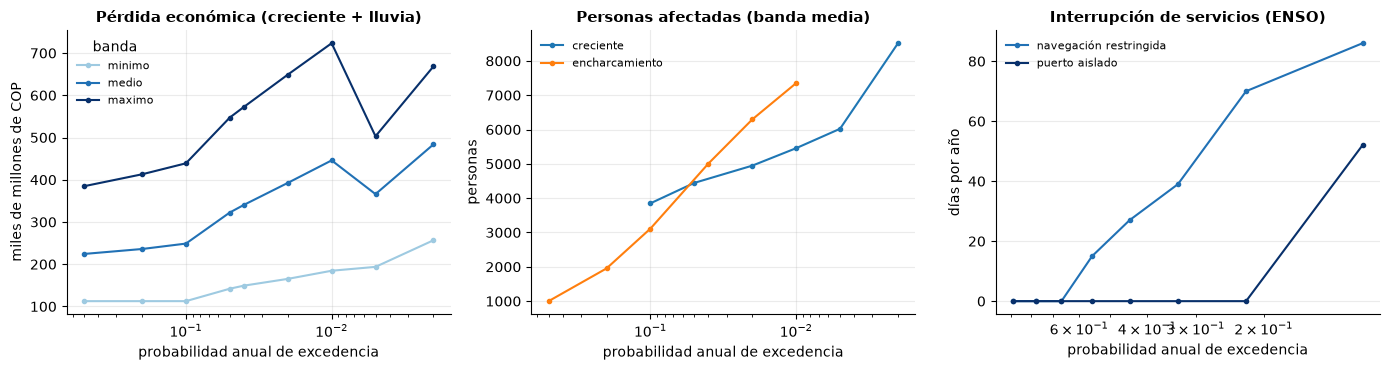

In [19]:
# Curva de excedencia total aproximada: suma de las curvas de las cadenas con periodos comunes (interpolación en 1/T)
T_com = sorted(set(T_jrc) | set(T_lluvia))
def curva_en(c, T_obj):
    p = 1 / np.array(sorted(c.index), dtype=float)
    return np.interp(1 / np.array(T_obj, dtype=float), p[::-1], c.sort_index().values[::-1], left=0)
total = {b_: pd.Series(curva_en(curvaA[b_], T_com) + curva_en(curvaB[b_], T_com), index=T_com) for b_ in BANDAS}
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for b_ in BANDAS:
    ax[0].plot(1 / np.array(T_com), total[b_].values / 1e3, marker="o", ms=3, color=COL_BANDA[b_], label=b_)
ax[0].set_xscale("log"); ax[0].invert_xaxis(); ax[0].set_xlabel("probabilidad anual de excedencia")
ax[0].set_ylabel("miles de millones de COP"); ax[0].set_title("Pérdida económica (creciente + lluvia)"); ax[0].legend(title="banda", fontsize=8)
for nombre, serie in {"creciente": pers_union["medio"], "encharcamiento": pers_B["medio"]}.items():
    ax[1].plot(1 / np.array(serie.index), serie.values, marker="o", ms=3, label=nombre)
ax[1].set_xscale("log"); ax[1].invert_xaxis(); ax[1].set_xlabel("probabilidad anual de excedencia")
ax[1].set_ylabel("personas"); ax[1].set_title("Personas afectadas (banda media)"); ax[1].legend(fontsize=8)
for c, col in zip(curvas_dias, ["#2171b5", "#08306b"]):
    ax[2].plot(curvas_dias[c]["prob_excedencia"], curvas_dias[c]["valor"], marker="o", ms=3, color=col, label=c)
ax[2].set_xscale("log"); ax[2].invert_xaxis(); ax[2].set_xlabel("probabilidad anual de excedencia")
ax[2].set_ylabel("días por año"); ax[2].set_title("Interrupción de servicios (ENSO)"); ax[2].legend(fontsize=8)
fig.tight_layout()

### Dónde se concentra la pérdida

El 10 % de las celdas con pérdida concentra el **58 %** de la pérdida anual esperada. Edificaciones alcanzadas por las dos cadenas: **606** (1.964 personas); por al menos una: **3.377**.

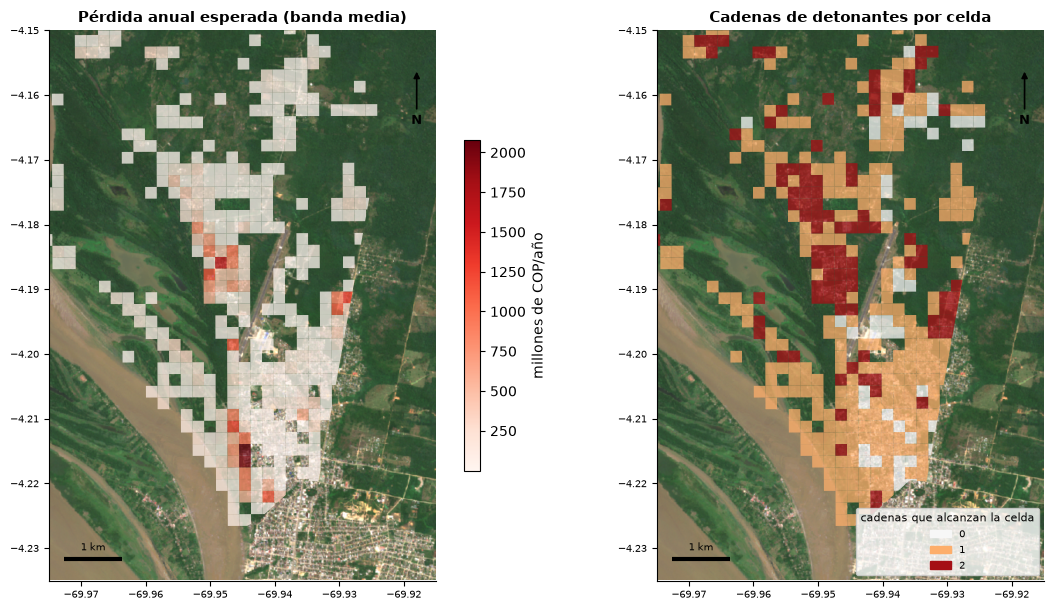

In [20]:
perd_eventos = {}
for b_ in ["medio"]:
    L_A = pd.DataFrame({t: perdida_creciente(b_, t)[0] * valor[b_] for t in T_jrc})
    L_B = pd.DataFrame({t: perdida_lluvia(b_, t)[0] * valor[b_] for t in T_lluvia})
def pae_por_edificio(L):
    L = L.copy()
    return L.apply(lambda fila: riesgo.perdida_anual_esperada(fila), axis=1)
edif["pae_creciente"] = pae_por_edificio(L_A).values / 1e6
edif["pae_lluvia"] = pae_por_edificio(L_B).values / 1e6
edif["pae_total"] = edif["pae_creciente"] + edif["pae_lluvia"]
edif["n_cadenas"] = (edif["pae_creciente"] > 0).astype(int) + (edif["pae_lluvia"] > 0).astype(int)
g = edif.groupby("id_celda")
malla["pae_total"] = g["pae_total"].sum().reindex(malla.index).fillna(0)
malla["pae_creciente"] = g["pae_creciente"].sum().reindex(malla.index).fillna(0)
malla["pae_lluvia"] = g["pae_lluvia"].sum().reindex(malla.index).fillna(0)
malla["n_cadenas_max"] = g["n_cadenas"].max().reindex(malla.index).fillna(0).astype(int)
fig, ax = plt.subplots(1, 2, figsize=(12, 6.2))
viz.mapa_celdas(malla[malla["pae_total"] > 0], "pae_total", ax=ax[0], cmap="Reds", etiqueta="millones de COP/año", titulo="Pérdida anual esperada (banda media)")
cats = ["0", "1", "2"]
malla["cadenas"] = pd.Categorical(malla["n_cadenas_max"].astype(str), categories=cats)
viz.mapa_celdas(malla[malla.n_edif > 0], "cadenas", ax=ax[1], categorias=cats, colores=["#f7f7f7", "#fdae6b", "#a50f15"],
                etiqueta="cadenas que alcanzan la celda", titulo="Cadenas de detonantes por celda")
fig.tight_layout()
top = malla["pae_total"].sort_values(ascending=False)
n10 = max(1, int((top > 0).sum() * 0.1))
display(Markdown(f"El 10 % de las celdas con pérdida concentra el **{100 * top.iloc[:n10].sum() / top.sum():.0f} %** de la pérdida anual esperada. "
                 f"Edificaciones alcanzadas por las dos cadenas: **{f((edif.n_cadenas == 2).sum())}** ({f(edif.loc[edif.n_cadenas == 2, 'poblacion'].sum())} personas); "
                 f"por al menos una: **{f((edif.n_cadenas >= 1).sum())}**."))
malla[["pae_total", "pae_creciente", "pae_lluvia", "n_cadenas_max"]].to_csv(fuentes.ruta("multiamenaza_celdas.csv"))

In [21]:
viz.pie(viz.nota_fuente("inundacion_jrc", "elevacion", "edificaciones", "poblacion") + " Parámetros ilustrativos de `multiamenaza`.")

*Fuente: JRC – Copernicus EMS (GloFAS) — Global river flood hazard maps v2.1 (RP10–RP500), LISFLOOD-FP; Copernicus DEM GLO-30 — DSM 30 m (TanDEM-X 2011–2015); Microsoft – Global ML Building Footprints — Huellas derivadas de imágenes (2014–2024), particionadas por quadkey; Kontur (GHSL, Facebook HRSL, Microsoft Buildings, Copernicus) — Kontur Population Colombia 2023-11-01. Parámetros ilustrativos de `multiamenaza`.*

**Lectura.** En la banda media, la pérdida anual esperada total es de unos **53 500 millones de COP por año**
(2,8 % del valor expuesto), con un rango de 20 200 a 131 600 millones entre la banda mínima y la máxima: el rango, de
6,5 veces, es parte del resultado. La cadena de la creciente aporta cerca de 70 %, el encharcamiento 28 % y los
vendavales 2 %. Como el contraste con las emergencias registradas indica que la cadena de la creciente sobrestima, el
total debe leerse como un **techo**. La pérdida se concentra: el 10 % de las celdas reúne 58 % de la pérdida anual
esperada, y 606 edificaciones (1 964 personas) quedan en el alcance de las dos cadenas. Ahí rinden más las medidas que
atienden la creciente y la lluvia a la vez, como el drenaje y la elevación de las viviendas más bajas
([3.1.e](31_inundacion/e_medidas.md), [3.6.e](36_lluvias_vendavales/e_medidas.md)).

## 8. Qué cambia en la gestión

El marco de seis etapas ordena las medidas de las páginas *e* según **dónde actúan en la cadena**: reducir la amenaza,
la exposición o la vulnerabilidad, y hacerlo para varias amenazas a la vez cuando comparten detonante. Las medidas se
mantienen en cada flujo ([3.1.e](31_inundacion/e_medidas.md), [3.3.e](33_erosion/e_medidas.md),
[3.6.e](36_lluvias_vendavales/e_medidas.md), [3.2.e](32_sequia/e_medidas.md)) y las prioridades transversales, en
la [síntesis](38_sintesis.ipynb).

:::{note} Limitaciones
- Los parámetros de `multiamenaza` son hipótesis de trabajo (ilustrativas) y deben validarse con la Alcaldía, el CMGRD
  y expertos locales; con ese juicio experto se reemplazarían las bandas por rangos acordados.
- Solo se cuantifica en pesos lo que tiene función de daño (inundación, erosión, encharcamiento, vendaval). Calor,
  incendio y dengue se leen en sus páginas y no entran en la pérdida económica.
- El modelo global de inundación del JRC (90 m) no conoce rellenos ni viviendas palafíticas: las cifras de la cadena
  de la creciente son un orden de magnitud.
- Las cadenas se suponen independientes en el tiempo; la persistencia entre años (La Niña tras El Niño) no se modela.
:::